# Auto-Tuning Gray-Scott Using Julia

# Setup

The setup is similar to the KernelAbstractions tutorial. The cells below activate the project environment, install and load the packages, and select the backend; first set `DEV` below to match your hardware.

In [1]:
# Pick your hardware: :NVIDIA, :AMD, :Metal, or :CPU
DEV = :Metal

:Metal

In [5]:
include("setup_notebook.jl")

  Activating project at `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks`
     Project No packages added to or removed from `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
    Manifest No packages added to or removed from `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Manifest.toml`
   Resolving package versions...
     Project No packages added to or removed from `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
    Manifest No packages added to or removed from `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutori

with_live_tuning_plot (generic function with 1 method)

Let's check the packages are installed correctly.

In [ ]:
Pkg.status()

Status `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
  [6e4b80f9] BenchmarkTools v1.8.0
  [3da002f7] ColorTypes v0.12.5
  [7073ff75] IJulia v1.34.4
  [682c06a0] JSON v1.13.4
⌃ [63c18a36] KernelAbstractions v0.10.4
  [d8e2316b] KernelTuner v1.1.0 `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/KernelTuner.jl`
  [dde4c033] Metal v1.12.0
  [91a5bcdd] Plots v1.41.7
  [92933f4c] ProgressMeter v1.13.0
  [6099a3de] PythonCall v0.9.37
Info Packages marked with ⌃ have new versions available and may be upgradable.


    Updating registry at `~/.julia/registries/General.toml`
   Installed HarfBuzz_jll ─────────── v100.15001.0+0
   Installed pocl_standalone_jll ──── v7.2.3+6
   Installed SPIRV_LLVM_Backend_jll ─ v23.1.4+1
   Installed KernelInterface ──────── v0.4.5
   Installed BFloat16s ────────────── v0.6.5
   Installed GPUToolbox ───────────── v3.5.1
   Installed Adapt ────────────────── v4.8.0
   Installed GPUCompiler ──────────── v2.21.0
   Installed KernelAbstractions ───── v0.10.5
  Installing 3 artifacts
   Installed artifact HarfBuzz              1.3 MiB
   Installed artifact SPIRV_LLVM_Backend    5.5 MiB
   Installed artifact pocl_standalone       29.7 MiB
    Updating `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
  [63c18a36] ↑ KernelAbstractions v0.10.4 ⇒ v0.10.5 [loaded: v0.10.4]
    Updating `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/j

In [7]:
if DEV == :NVIDIA
    using CUDA
    ArrayKA = CUDA.CuArray
    Backend = CUDA.CUDABackend()
elseif DEV == :AMD
    using AMDGPU
    ArrayKA = AMDGPU.ROCArray
    Backend = AMDGPU.ROCBackend()
elseif DEV == :Metal
    using Metal
    ArrayKA = Metal.MtlArray
    Backend = Metal.MetalBackend()
elseif DEV == :CPU
    ArrayKA = Array
    Backend = CPU()
    @warn "Using CPU backend. This will be very slow and might not work for all use cases in this tutorial. Consider using a GPU backend."
else
    error("Unknown DEV = $DEV. Use :NVIDIA, :AMD, :Metal, or :CPU.")
end

MetalBackend()

# 1. The Gray-Scott Reaction-Diffusion Model

The Gray-Scott Reaction-Diffusion model is a mathematical model used to describe how two interacting substances, typically denoted as $U$ and $V$, evolve over time in a spatial domain. This model captures the combined effects of chemical reactions and diffusion, leading to complex pattern formations such as spots, stripes, and waves, which resemble natural phenomena like animal skin patterns or chemical reactions in a petri dish. 

## The Kernel

This kernel is a relatively simple one; for more information on this implementation see [the KernelAbstractions tutorial](). We'll start by adding the workgroup size as tunable parameters. For this, use Julia's `::Val{} where` syntax. This compiles to a constant and a default can be provided so your kernel is still completely executable outside of autotuning contexts.


In [8]:
using KernelAbstractions

# 5-point Laplacian, same as the reference CPU implementation
@inline function laplacian(A, x, y, dx)
    @inbounds DAx = (A[x-1, y] - (2 * A[x, y]) + A[x+1, y]) / dx
    @inbounds DAy = (A[x, y-1] - (2 * A[x, y]) + A[x, y+1]) / dx
    return DAx + DAy
end

# BX × BY is the workgroup size: Kernel Tuner passes each tunable parameter to the kernel as a `Val` argument
@kernel function gs_gpu_kernel!(Uout, Vout, @Const(U), @Const(V), D_u, D_v, F, k, dt, dx, nx, ny, noise,
        ::Val{BX} = Val(16), ::Val{BY} = Val(16)) where {BX, BY}
    x, y = @index(Global, NTuple)

    if (1 < x < nx) && (1 < y < ny)
        u = @inbounds U[x, y]
        v = @inbounds V[x, y]

        ΔU = laplacian(U, x, y, dx)
        ΔV = laplacian(V, x, y, dx)
        UVV = u * v * v
        Nr = noise == 0 ? zero(u) : noise * randn(Float32)
        DU = D_u * ΔU - UVV + F * (1 - u) + Nr
        DV = D_v * ΔV + UVV - (F + k) * v
        newU = u + DU * dt
        newV = v + DV * dt

        @inbounds Uout[x, y] = newU
        @inbounds Vout[x, y] = newV
    end
end

gs_gpu_kernel! (generic function with 4 methods)

Now that we have our kernel source code, it might be nice to see what it actually does. Don't worry about the implementation details of the cell below, they're just to draw a nice animation. 


In [9]:
function simulate_gs_gpu(n = 500 #=Grid size=#, nsteps = 10000 #=Number of iterations=# ;
                        init_multi = 0.5,
                        noise = 0.0f0,
                        D_u = 0.16f0,
                        D_v = 0.08f0,
                        F = 0.035f0,
                        k = 0.06f0,
                        dt = 1.0f0,
                        dx = 1.0f0,
                        plot_every = 500)

    U = Float32.(rand(0.0:0.001:0.1, n, n))
    V = zeros(Float32, n, n)

    n_mid = div(n, 2)
    U[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(init_multi)
    V[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(0.5 * init_multi)

    U1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    U2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    KernelAbstractions.copyto!(Backend, U1, U)
    KernelAbstractions.copyto!(Backend, V1, V)
    KernelAbstractions.copyto!(Backend, U2, U)
    KernelAbstractions.copyto!(Backend, V2, V)

    kernel = gs_gpu_kernel!(Backend, (cld(n, 16), cld(n, 16)))
    readU, readV, writeU, writeV = U1, V1, U2, V2

    prog = Progress(div(nsteps, plot_every))
    plt = Plots.plot(title="Gray-Scott Model", xlabel="X", ylabel="Y")

    anim = Plots.@animate for t in 1:div(nsteps, plot_every)
        for _ in 1:plot_every
            kernel(writeU, writeV, readU, readV, D_u, D_v, F, k, dt, dx, n, n, noise, ndrange=(n, n))
            readU, readV, writeU, writeV = writeU, writeV, readU, readV
        end

        KernelAbstractions.copyto!(Backend, U, readU)
        KernelAbstractions.synchronize(Backend)

        next!(prog)
        Plots.heatmap!(plt, U, color=cgrad([:black, :blue, :white]), clims=extrema(U), title="Gray-Scott Model", dpi=110)
    end
    gif(anim, "gs_ka.gif"; fps=10)
end

simulate_gs_gpu (generic function with 3 methods)

Let's see our Gray-Scott Model in action:

Progress: 100%|█████████████████████████████████████████| Time: 0:00:23
[ Info: Saved animation to /Users/fjwillemsen/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/gs_ka.gif


 25.228491 seconds (415.51 M allocations: 13.940 GiB, 5.04% gc time, 26.51% compilation time: 22% of which was recompilation)


Plots.AnimatedGif("/Users/fjwillemsen/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/gs_ka.gif")
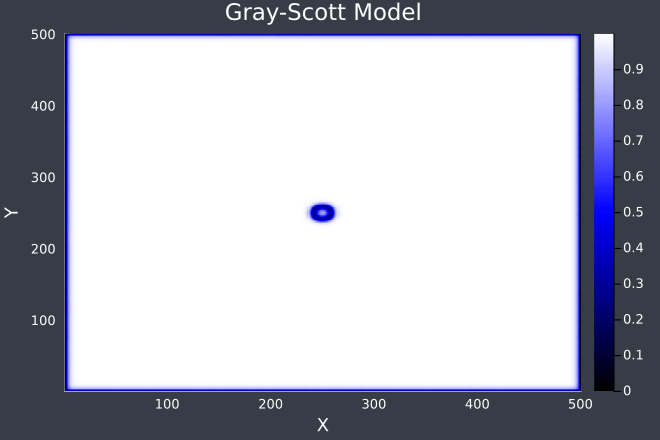

In [10]:
@time simulate_gs_gpu(500, 10000)

# 2. Autotuning the Kernel

We can see the kernel works. But can we improve its performance? Let's tune the workgroup sizes we added earlier and find out.
Now that we have our kernel source code in a file, we can get started on the autotuning! We start by generating some input data that we will use to run our GPU kernel.

In [11]:
# parameters
n = 500
init_multi = 0.5

U = Float32.(rand(0.0:0.001:0.1, n, n))
V = zeros(Float32, n, n)

n_mid = div(n, 2)
U[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(1.0 * init_multi)
V[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(0.5 * init_multi)

U1 = KernelAbstractions.allocate(Backend, Float32, n, n)
V1 = KernelAbstractions.allocate(Backend, Float32, n, n)
U2 = KernelAbstractions.allocate(Backend, Float32, n, n)
V2 = KernelAbstractions.allocate(Backend, Float32, n, n)
KernelAbstractions.copyto!(Backend, U1, U)
KernelAbstractions.copyto!(Backend, V1, V)
KernelAbstractions.copyto!(Backend, U2, U)
KernelAbstractions.copyto!(Backend, V2, V)

500×500 MtlMatrix{Float32, Metal.SharedStorage}:
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0 

## 2.1. Tuning the workgroup size

We start with the simple kernel `gs_gpu_kernel!`, where every work-item computes exactly one grid point. The only thing we can tune here is the **workgroup size**: how many work-items are grouped together, and in what shape (`block_size_x` × `block_size_y`).

Kernel Tuner uses `block_size_x` and `block_size_y` as the workgroup dimensions by default, and by default divides the problem size by them to get the number of workgroups, so we don't need to specify `grid_div_x`/`grid_div_y` here.

In [12]:
using KernelTuner

arguments = [U1, V1, U2, V2, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0]
tune_params = [
    ("block_size_x", [8, 16, 32, 64, 128]),  # workgroup size along x
    ("block_size_y", [1, 2, 4, 8, 16]),      # workgroup size along y
]

results_wg, env_wg = KernelTuner.tune_kernel(
    "gs_gpu_kernel!",
    get_cell_by_tag("gs_gpu_kernel"),   # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
    (n, n),
    arguments,
    tune_params,
    # each workgroup covers (block_size_x) × (block_size_y) grid points
    grid_div_x=("block_size_x", 1), grid_div_y=("block_size_y", 1),
    lang="Julia",
    verbose=true,
)

best_wg = (Int(env_wg["best_config"]["block_size_x"]), Int(env_wg["best_config"]["block_size_y"]))

Using: Apple M5 Pro
Searchspace has 24 configurations after restrictions.
block_size_x=8, block_size_y=1, time=0.614ms
block_size_x=8, block_size_y=2, time=0.475ms
block_size_x=8, block_size_y=4, time=0.386ms
block_size_x=8, block_size_y=8, time=0.368ms
block_size_x=8, block_size_y=16, time=0.358ms
block_size_x=16, block_size_y=1, time=0.312ms
block_size_x=16, block_size_y=2, time=0.279ms
block_size_x=16, block_size_y=4, time=0.443ms
block_size_x=16, block_size_y=8, time=0.317ms
block_size_x=16, block_size_y=16, time=0.397ms
block_size_x=32, block_size_y=1, time=0.258ms
block_size_x=32, block_size_y=2, time=0.297ms
block_size_x=32, block_size_y=4, time=0.405ms
block_size_x=32, block_size_y=8, time=0.273ms
block_size_x=32, block_size_y=16, time=0.240ms
block_size_x=64, block_size_y=1, time=0.256ms
block_size_x=64, block_size_y=2, time=0.345ms
block_size_x=64, block_size_y=4, time=0.406ms
block_size_x=64, block_size_y=8, time=0.348ms
block_size_x=64, block_size_y=16, time=0.345ms
block_s

(32, 16)

While Kernel Tuner has printed the configurations as it evaluated them, we may be interested in more detailed results. Have a look at the values returned by `tune_kernel` and discover what they entail.

In [13]:
display(results_wg)
display(env_wg)

24-element Vector{Dict}:
 Dict{String, Any}("block_size_y" => 1.0, "times" => Any[0.4045, 0.396125, 0.7465, 0.630833, 0.7691666466295719, 0.727041323314786, 0.416833], "compile_time" => 4.179292009212077, "strategy_time" => 0.0, "benchmark_time" => 111.6856670123525, "verification_time" => 0, "time" => 0.6144164949907264, "timestamp" => "2026-11-06 02:07:53.102276+00:00", "framework_time" => 38.857348790863334, "block_size_x" => 8.0…)
 Dict{String, Any}("block_size_y" => 2.0, "times" => Any[0.31862432331478596, 0.608167, 0.5852076466295719, 0.7003746466295719, 0.3211246466295719, 0.31879232331478596, 0.31862532331478594], "compile_time" => 4.09879203652963, "strategy_time" => 0.0, "benchmark_time" => 135.24274999508634, "verification_time" => 0, "time" => 0.4753819310863813, "timestamp" => "2026-11-06 02:07:53.241815+00:00", "framework_time" => 38.857348790863334, "block_size_x" => 8.0…)
 Dict{String, Any}("block_size_y" => 4.0, "times" => Any[0.294417, 0.5892496466295719, 0.5762923815

Dict{String, Any} with 13 entries:
  "compiler_options"        => Any[]
  "total_strategy_time"     => 0.0
  "total_framework_time"    => 932.576
  "device_name"             => "Apple M5 Pro"
  "pci_bus_id"              => nothing
  "total_compile_time"      => 94.9789
  "total_verification_time" => 0
  "overhead_time"           => 516.626
  "compute_capability"      => nothing
  "best_config"             => Dict{String, Any}("block_size_y"=>16.0, "times"=…
  "iterations"              => 7
  "total_benchmark_time"    => 3153.87
  "uuid"                    => nothing

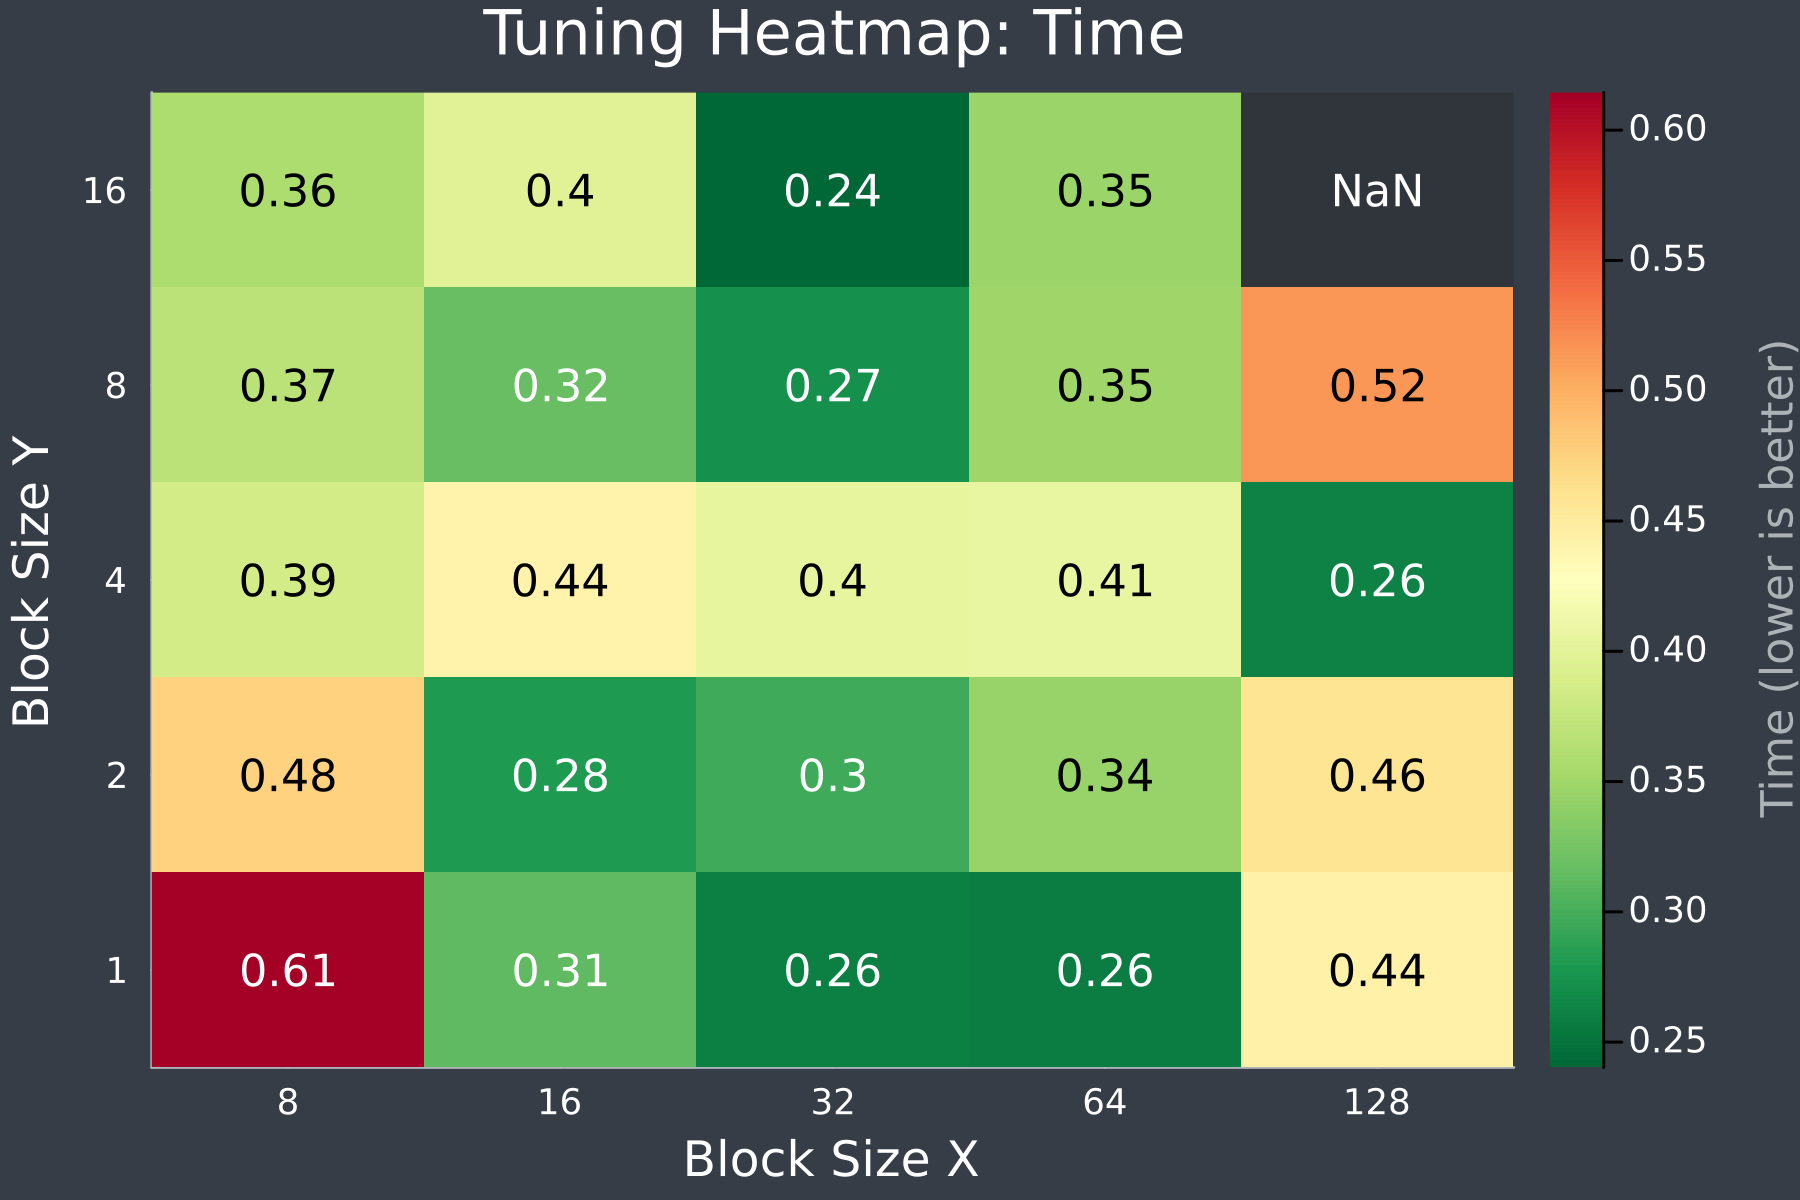

In [14]:
plot_heatmap_tuning_results(results_wg, "block_size_x", "block_size_y")

We can use the heatmap to analyze potentially interesting regions. 
What's going on with the missing configuration for `(128, 16)`? By default, Kernel Tuner applies a restriction that the product of the block sizes can not exceed 1024 as this is a hard limit for GPU programming models. We'll find out more about restrictions later on. 

## 2.2. Tuning the tile size

Of course we can do more than just tuning the workgroup sizes. Tiling, for example: a more advanced implementation that gives each work item a `P` × `Q` tile of the grid (`P` along `y`, `Q` along `x`). 
This is implemented in kernel `gs_gpu_kernel_tuned!`, where each work-item computes a `Q` × `P` tile of grid points. Each workgroup now covers `(block_size_x * Q) × (block_size_y * P)` grid points, so we tell Kernel Tuner to divide the problem size by both with `grid_div_x` and `grid_div_y`. 
The kernel also receives the workgroup size `BX` × `BY` as compile-time parameters: Kernel Tuner passes every tunable parameter to a Julia kernel as a `Val` argument, in the order they are defined, so the signature needs a slot for each of them (even though the workgroup size itself is set at launch).

In [15]:
using KernelAbstractions

# Fill per-work-item halo cache tile[q, p] = A[x1+q-2, y1+p-2] (out-of-bounds → zero).
# tile is `@private Float32 (Q + 2, P + 2)` — compile-time size from kernel parameters P, Q.
@inline function load_tile!(tile, A, x1, y1, nx, ny, ::Val{P}, ::Val{Q}) where {P, Q}
    @inbounds for q in 1:(Q + 2), p in 1:(P + 2)
        x = x1 + q - 2
        y = y1 + p - 2
        if 1 <= x <= nx && 1 <= y <= ny
            tile[q, p] = A[x, y]
        else
            tile[q, p] = zero(eltype(A))
        end
    end
    return
end

# Laplacian at tile indices (q, p) in 1:Q, 1:P — same 5-point formula as the CPU reference.
@inline function laplacian_tile(tile, q, p, dx)
    u = tile[q + 1, p + 1]
    @inbounds ux_m = tile[q, p + 1]
    @inbounds ux_p = tile[q + 2, p + 1]
    @inbounds uy_m = tile[q + 1, p]
    @inbounds uy_p = tile[q + 1, p + 2]
    ((ux_m - 2 * u + ux_p) + (uy_m - 2 * u + uy_p)) / dx
end

@kernel function gs_gpu_kernel_tiled!(Uout, Vout, @Const(U), @Const(V),
        D_u, D_v, F, k, dt, dx, nx, ny, noise, ::Val{P}, ::Val{Q}, ::Val{BX}, ::Val{BY}) where {P, Q, BX, BY}
    # Section 1: get indices
    i, j = @index(Global, NTuple)
    x1 = (i - 1) * Q + 1
    y1 = (j - 1) * P + 1

    # Section 2: allocate register memory and get data
    tileU = @private Float32 (Q + 2, P + 2)
    tileV = @private Float32 (Q + 2, P + 2)
    stepU = @private Float32 (Q, P)
    stepV = @private Float32 (Q, P)

    if (x1 < nx) && (x1 + Q > 2)
        load_tile!(tileU, U, x1, y1, nx, ny, Val(P), Val(Q))
        load_tile!(tileV, V, x1, y1, nx, ny, Val(P), Val(Q))

        # Section 3: calculate Laplacians (values → private step tile)
        for q in 1:Q, p in 1:P
            if (1 < x1 + q - 1 < nx) && (1 <  y1 + p - 1 < ny)
                u = tileU[q + 1, p + 1]
                v = tileV[q + 1, p + 1]
                ΔU = laplacian_tile(tileU, q, p, dx)
                ΔV = laplacian_tile(tileV, q, p, dx)
                UVV = u * v * v
                Nr = noise == 0 ? zero(u) : noise * randn(Float32)
                DU = D_u * ΔU - UVV + F * (1 - u) + Nr
                DV = D_v * ΔV + UVV - (F + k) * v
                stepU[q, p] = u + DU * dt
                stepV[q, p] = v + DV * dt
            end
        end

        # Section 4: global writes
        for q in 1:Q, p in 1:P
            x = x1 + q - 1
            y = y1 + p - 1
            if (1 < x < nx) && (1 < y < ny)
                @inbounds Uout[x, y] = stepU[q, p]
                @inbounds Vout[x, y] = stepV[q, p]
            end
        end
    end
end

gs_gpu_kernel_tiled! (generic function with 4 methods)

Next, we tune only the tile size `P` × `Q`, keeping the best workgroup size we found in step 1 fixed. 

In [16]:
using KernelTuner

arguments = [U1, V1, U2, V2, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0]
tune_params = [
    ("P", [1, 2, 4, 8, 16]),                    # tile size per work-item along y
    ("Q", [1, 2, 4, 8, 16]),                    # tile size per work-item along x
    ("block_size_x", [best_wg[1]]),             # keep the best workgroup size from step 1 fixed
    ("block_size_y", [best_wg[2]]),
]

results_ti, env = KernelTuner.tune_kernel(
    "gs_gpu_kernel_tiled!",
    get_cell_by_tag("gs_gpu_kernel_tiled"), # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
    (n, n),
    arguments,
    tune_params,
    # each workgroup covers (block_size_x * Q) × (block_size_y * P) grid points
    grid_div_x=("block_size_x", "Q"), grid_div_y=("block_size_y", "P"),
    lang="Julia",
    verbose=true
)

display(results_ti)

Using: Apple M5 Pro
Searchspace has 25 configurations after restrictions.
P=1, Q=1, block_size_x=32, block_size_y=16, time=0.340ms
P=1, Q=2, block_size_x=32, block_size_y=16, time=0.427ms
P=1, Q=4, block_size_x=32, block_size_y=16, time=0.461ms
P=1, Q=8, block_size_x=32, block_size_y=16, time=0.451ms
P=1, Q=16, block_size_x=32, block_size_y=16, time=0.487ms
P=2, Q=1, block_size_x=32, block_size_y=16, time=0.266ms
P=2, Q=2, block_size_x=32, block_size_y=16, time=0.273ms
P=2, Q=4, block_size_x=32, block_size_y=16, time=0.469ms
P=2, Q=8, block_size_x=32, block_size_y=16, time=0.397ms
P=2, Q=16, block_size_x=32, block_size_y=16, time=0.438ms
P=4, Q=1, block_size_x=32, block_size_y=16, time=0.254ms
P=4, Q=2, block_size_x=32, block_size_y=16, time=0.418ms
P=4, Q=4, block_size_x=32, block_size_y=16, time=0.345ms
P=4, Q=8, block_size_x=32, block_size_y=16, time=0.483ms
P=4, Q=16, block_size_x=32, block_size_y=16, time=0.946ms
P=8, Q=1, block_size_x=32, block_size_y=16, time=0.470ms
P=8, Q=2, b

25-element Vector{Dict}:
 Dict{String, Any}("strategy_time" => 0.0, "Q" => 1.0, "timestamp" => "2026-11-06 02:07:59.378214+00:00", "time" => 0.3398402299364706, "block_size_x" => 32.0, "times" => Any[0.6482499699443579, 0.286166, 0.27858402815201877, 0.27233364662957193, 0.6015837048372328, 0.312541, 0.287833], "compile_time" => 6.131083006039262, "verification_time" => 0, "framework_time" => 15.181789798679137, "P" => 1.0…)
 Dict{String, Any}("strategy_time" => 0.0, "Q" => 2.0, "timestamp" => "2026-11-06 02:07:59.515590+00:00", "time" => 0.4274794357783844, "block_size_x" => 32.0, "times" => Any[0.5041246466295719, 0.6010419699443579, 0.5161666466295719, 0.619084, 0.28875, 0.28475032331478595, 0.2550836747815907], "compile_time" => 6.132583017461002, "verification_time" => 0, "framework_time" => 15.181789798679137, "P" => 1.0…)
 Dict{String, Any}("strategy_time" => 0.0, "Q" => 4.0, "timestamp" => "2026-11-06 02:07:59.657394+00:00", "time" => 0.4610972741209915, "block_size_x" => 32.0,

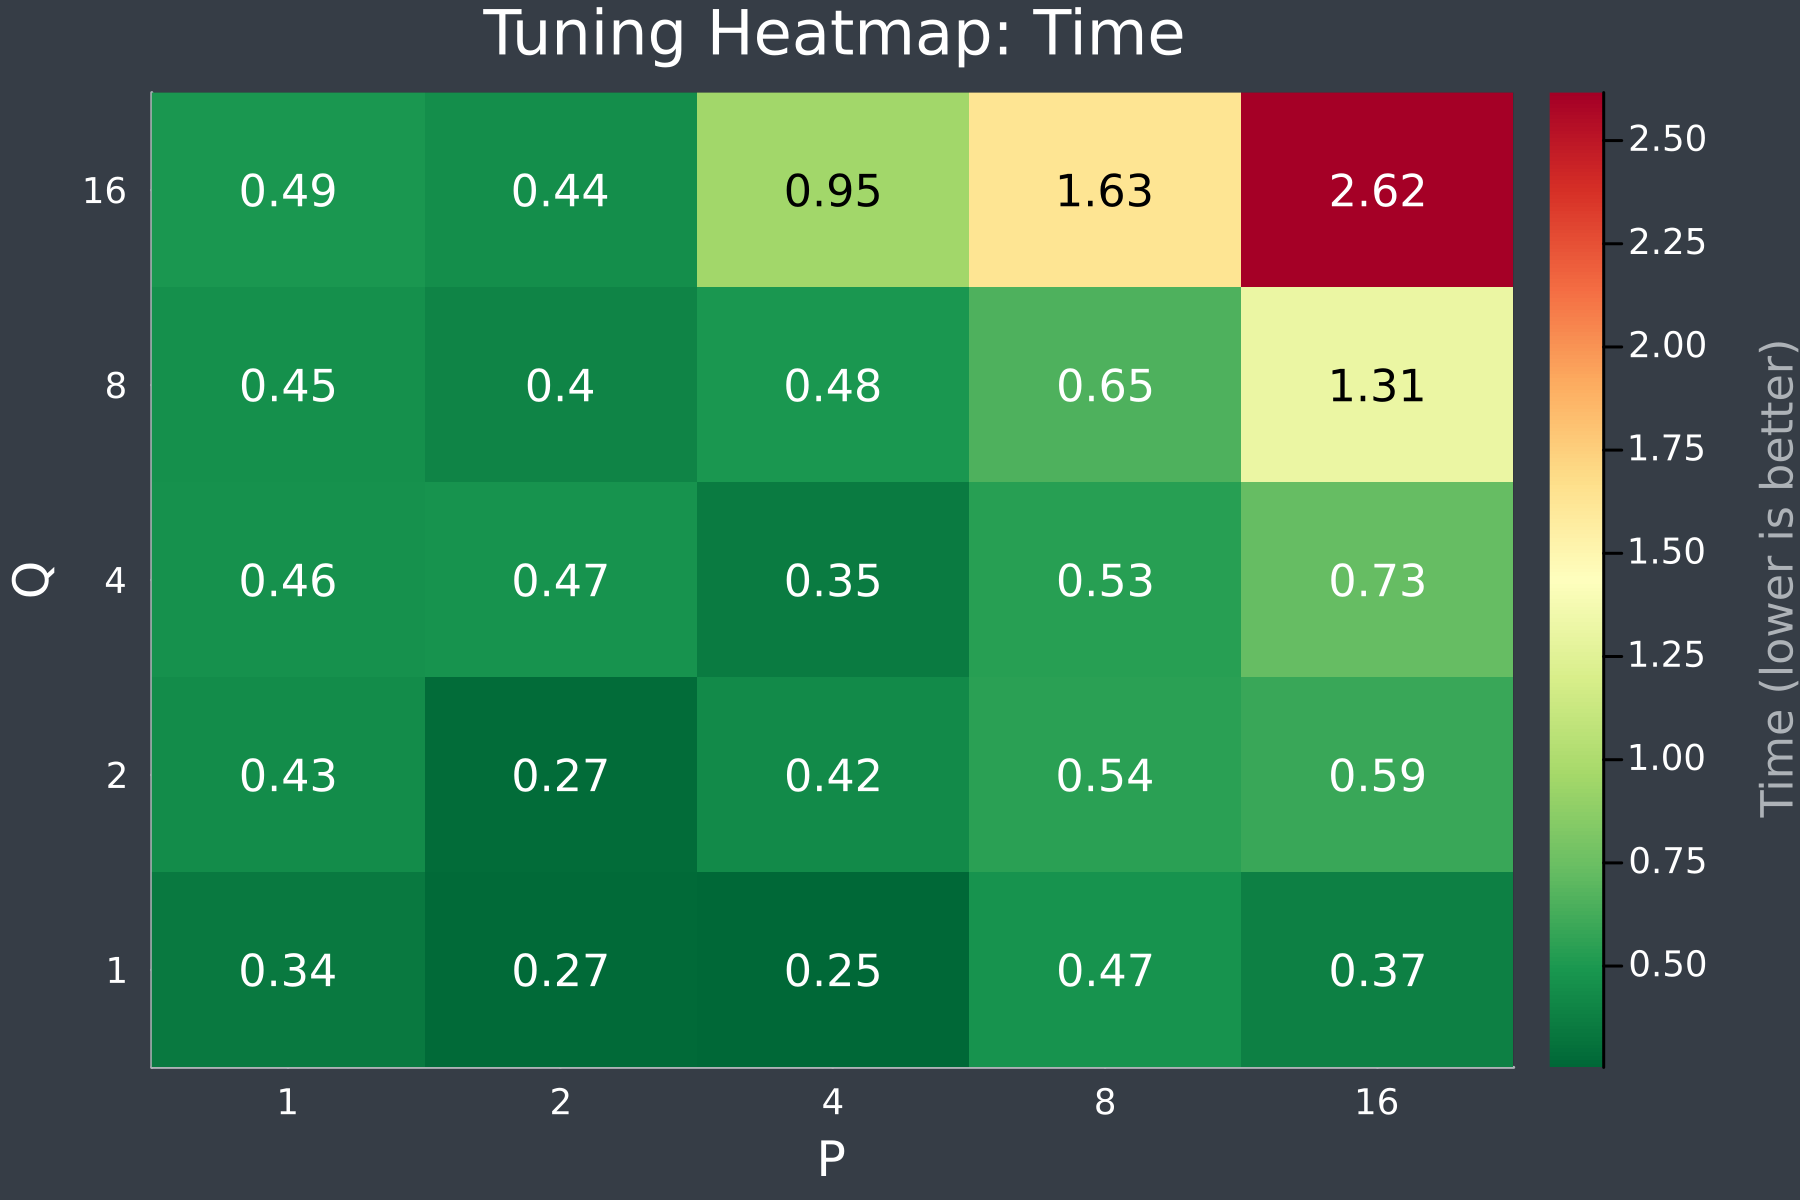

In [17]:
plot_heatmap_tuning_results(results_ti, "P", "Q")

# 3. Expanding the Tuning

## 3.1. Restrictions

To reduce configurations that would not work (either because they can not compile or are always going to be slow), we can use Kernel Tuner's `restriction` setting. This takes a list of strings of expressions. Only configurations that meet all the restriction conditions are left in the searchspace. Let's define a restriction for the product of the block sizes. 

In [20]:
# keep workgroups between one SIMD-group (32) and the hardware maximum (1024 work-items)
restrictions = ["32 <= block_size_x * block_size_y <= 1024"]

1-element Vector{String}:
 "32 <= block_size_x * block_size_y <= 1024"

## 3.2 Optimization Strategies

By default, Kernel Tuner explores ("brute forces") the searchspace. This is often not feasible. As such, Kernel Tuner provides a wide range of optimization strategies, [specified here](https://kerneltuner.github.io/kernel_tuner/stable/optimization.html#optimization-strategies). 

In [43]:
strategy = "genetic_algorithm"
# strategy = "dual_annealing"
# strategy = "random_sample"
# strategy = "bayes_opt"

"genetic_algorithm"

# 3.3. Limits

In addition, we can introduce a limit on the number of evaluations or the time taken for the tuning. This means that Kernel Tuner will stop searching after this limit is hit and return the best configuration found so far. This is set with the keys `time_limit` (in seconds) or `max_feval`, along with any additional strategy-specific options, in a list of tuples passed to `strategy_options`. 

In [ ]:
# strategy_options=[("max_fevals", 100)]
strategy_options=[("time_limit", 30)]

1-element Vector{Tuple{String, Int64}}:
 ("time_limit", 20)

## 3.4. Caching & Combining It All

The best tile size may depend on the workgroup size and vice versa, so finally we tune both at the same time. Note how much larger the search space becomes. 

Because the searchspace is getting larger, it might be convenient to save the results in a file, which also allows us to pick up where we left in case the tuning is interrupted. We can pass the `cache` argument with a filename of our choice. While tuning, the cache file grows one configuration at a time; the helper `with_live_tuning_plot` (defined in the setup) reads it in the background and keeps a scatterplot of the results so far up to date. If you run the cell again after execution, you'll notice it now immediately pulls all results from the cachefile.

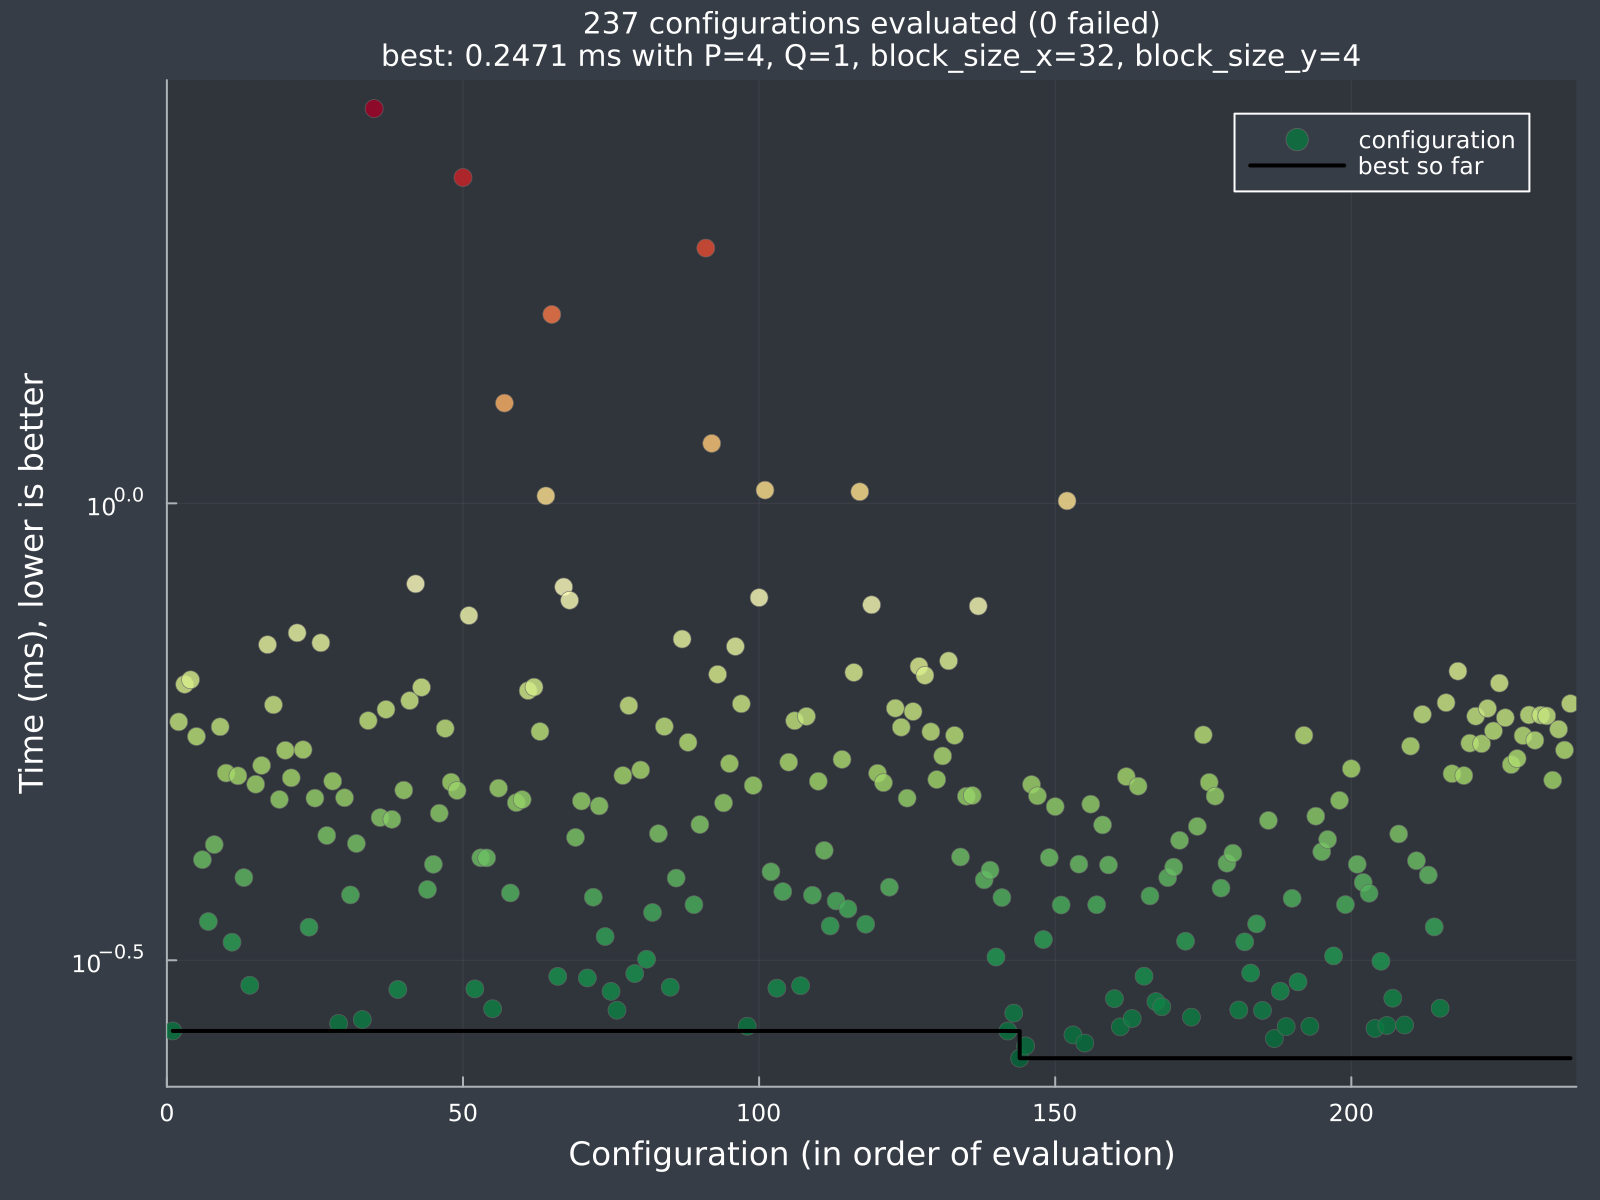

Using: Apple M5 Pro
Searchspace has 525 configurations after restrictions.
P=8, Q=2, block_size_x=32, block_size_y=16, time=0.479ms
P=4, Q=16, block_size_x=16, block_size_y=2, time=0.772ms
P=8, Q=1, block_size_x=64, block_size_y=8, time=0.387ms
P=4, Q=4, block_size_x=8, block_size_y=16, time=0.397ms
P=2, Q=4, block_size_x=16, block_size_y=2, time=0.319ms
P=8, Q=2, block_size_x=8, block_size_y=4, time=0.370ms
P=1, Q=4, block_size_x=16, block_size_y=8, time=0.265ms
P=1, Q=2, block_size_x=128, block_size_y=1, time=0.277ms
P=4, Q=1, block_size_x=32, block_size_y=4, time=0.247ms
P=2, Q=2, block_size_x=64, block_size_y=1, time=0.255ms
P=4, Q=8, block_size_x=64, block_size_y=4, time=0.492ms
P=2, Q=2, block_size_x=128, block_size_y=4, time=0.479ms
P=1, Q=8, block_size_x=32, block_size_y=16, time=0.333ms
P=2, Q=8, block_size_x=64, block_size_y=1, time=0.410ms
P=2, Q=8, block_size_x=64, block_size_y=4, time=0.466ms
P=1, Q=8, block_size_x=64, block_size_y=1, time=0.363ms
P=8, Q=16, block_size_x=6

(Dict[Dict{String, Any}("strategy_time" => 0.0053028846153846156, "Q" => 2.0, "timestamp" => "2026-11-06 04:21:00.015649+00:00", "time" => 0.47895150938400627, "block_size_x" => 32.0, "times" => Any[0.361125323314786, 0.5766673815224469, 0.6525837048372328, 0.6388749699443579, 0.344167, 0.332666, 0.32875], "compile_time" => 6.645207991823554, "verification_time" => 0, "framework_time" => 18.234206759227327, "P" => 8.0…), Dict{String, Any}("strategy_time" => 0.0053028846153846156, "Q" => 16.0, "timestamp" => "2026-11-06 04:21:00.159640+00:00", "time" => 0.7719024849721788, "block_size_x" => 16.0, "times" => Any[0.4894160281520188, 0.764166323314786, 0.7869579699443578, 0.7872913233147859, 0.728958, 0.7918753233147859, 0.7721659699443578], "compile_time" => 6.0425830306485295, "verification_time" => 0, "framework_time" => 18.234206759227327, "P" => 4.0…), Dict{String, Any}("strategy_time" => 0.0053028846153846156, "Q" => 4.0, "timestamp" => "2026-11-06 04:21:00.159848+00:00", "time" => 0

In [ ]:
using KernelTuner

arguments = [U1, V1, U2, V2, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0]
tune_params = [
    ("P", [1, 2, 4, 8, 16]),                    # tile size per work-item along y
    ("Q", [1, 2, 4, 8, 16]),                    # tile size per work-item along x
    ("block_size_x", [8, 16, 32, 64, 128]),     # workgroup size along x
    ("block_size_y", [1, 2, 4, 8, 16]),         # workgroup size along y
]

cachefile = "gs_gpu_kernel_tuned.json"

# the plot above the tuning output is redrawn as configurations are added to the cache file (Kernel Tuner appends ".json")
results_wg_ti, env = with_live_tuning_plot(cachefile) do
    KernelTuner.tune_kernel(
        "gs_gpu_kernel_tiled!",
        get_cell_by_tag("gs_gpu_kernel_tiled"), # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
        (n, n),
        arguments,
        tune_params,
        restrictions=restrictions,
        # each workgroup covers (block_size_x * Q) × (block_size_y * P) grid points
        grid_div_x=("block_size_x", "Q"), grid_div_y=("block_size_y", "P"),
        lang="Julia",
        verbose=true,
        cache=cachefile,
        strategy=strategy,
        strategy_options=strategy_options,
    )
end

# if you'd like to run the cell again without the cached results, uncomment the following line
# rm(cachefile)

# 4. Advanced Tuning Options

## 4.1. Verification

## 4.2 Energy Tuning

## 4.3 More Metrics